<div style="display: flex; background-color: RGB(255,114,0);" >
<h1 style="margin: auto; padding: 30px; ">ANALYSE DU STOCK ET DES VENTES DU SITE BOTTLENECK</h1>
</div>

# OBJECTIF DE CE NOTEBOOK

Bienvenue dans l'outil plébiscité par les analystes de données Jupyter.

Il s'agit d'un outil permettant de mixer et d'alterner code, texte et graphiques.

Cet outil est formidable pour plusieurs raisons:

+ Il permet de tester des lignes de codes au fur et à mesure de votre rédaction, de constater immédiatement le résultat d'une instruction, de la corriger si nécessaire.
+ Il permet aussi de rédiger du texte pour expliquer l'approche suivie ou les résultats d'une analyse et de le mettre en forme grâce à du code html ou plus simple avec **Markdown**
+ Il est possible d'ajouter des graphiques

Pour vous aider dans vos premiers pas à l'usage de Jupyter et de Python, nous avons rédigé ce notebook en vous indiquant les instructions à suivre.

Il vous suffit pour cela de saisir le code Python répondant à l'instruction donnée.

Vous verrez de temps à autre le code Python répondant à une instruction donnée mais cela est fait pour vous aider à comprendre la nature du travail qui vous est demandé.

Et gardez à l'esprit qu'il n'y a pas de solution unique pour résoudre un problème et qu'il y a autant de résolutions de problèmes que de développeurs ;)...



<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.1 - Importation des librairies</h3>
</div>

In [2]:
#Importation de la librairie Pandas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [3]:
#Importation de la librairie plotly express
import plotly.express as px

In [4]:
#Trouver dans Google l'instruction permettant d'afficher toutes les colonnes d'un dataframe
#Saisir dans Google les mots clés "display all columns dataframe Pandas" par exemple.
#Dans les résultats de la recherche, privilégier les solutions provenant de Stack Overflow ou Medium

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.2 - Chargements des fichiers</h3>
</div>

In [5]:
#Importation du fichier web.xlsx
df_web = pd.read_excel("DATA/web.xlsx")
#Importation du fichier erp.xlsx
df_erp=pd.read_excel("DATA/erp.xlsx")
#Importation du fichier liaison.xlsx
df_liaison=pd.read_excel("DATA/liaison.xlsx")


C:\Users\AMAN\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():
C:\Users\AMAN\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():
C:\Users\AMAN\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1 - Analyse exploratoire du fichier erp.xlsx</h3>
</div>

In [6]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(df_erp.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_erp.shape[1]))

Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 6 colonne(s)


In [7]:
#Consulter le nombre de colonnes
#La nature des données dans chacune des colonnes
#Le nombre de valeurs présentes dans chacune des colonnes
df_erp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      825 non-null    int64  
 1   onsale_web      825 non-null    int64  
 2   price           825 non-null    float64
 3   stock_quantity  825 non-null    int64  
 4   stock_status    825 non-null    object 
 5   purchase_price  825 non-null    float64
dtypes: float64(2), int64(3), object(1)
memory usage: 38.8+ KB


In [8]:
#Afficher les 5 premières lignes de la table
df_erp.head()


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,outofstock,23.77


In [9]:
#Vérifier si il y a des lignes en doublon dans la colonne product_id
df_erp.duplicated(subset=['product_id']).sum()


np.int64(0)

In [10]:
df_erp['product_id'].is_unique

True

In [11]:
#Afficher les valeurs distinctes de la colonne stock_status
#À quelle(s) autre(s) colonne(s) sont-elles liées ?
df_erp['stock_status'].unique()




array(['instock', 'outofstock'], dtype=object)

La colonne stock_status est liee a la colonne stock_quantity

In [12]:
#Création d'une colonne "stock_status_2"
#La valeur de cette deuxième colonne sera fonction de la valeur dans la colonne "stock_quantity"
#Si la valeur de la colonne "stock_quantity" est nulle, renseigner "outofstock" sinon mettre "instock"
df_erp['stock_status_2']= np.where(df_erp['stock_quantity']==0,'outofstock','instock')
df_erp.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
0,3847,1,24.2,16,instock,12.88,instock
1,3849,1,34.3,10,instock,17.54,instock
2,3850,1,20.8,0,outofstock,10.64,outofstock
3,4032,1,14.1,26,instock,6.92,instock
4,4039,1,46.0,3,outofstock,23.77,instock


In [13]:
#Vérifions que les 2 colonnes sont identiques:
#Les 2 colonnes sont strictement identiques si les valeurs de chaque ligne sont strictement identiques 2 à 2
#La comparaison de 2 colonnes peut se réaliser simplement avec l'instruction ci-dessous:
print('nombre de ligne qui ne correspond pas :',(df_erp["stock_status"] != df_erp["stock_status_2"]).sum())
df_erp["stock_status"] == df_erp["stock_status_2"]

#Le résultat est l'affichage de True ou False pour chacune des lignes du dataset
#C'est un bon début, mais difficile à exploiter

nombre de ligne qui ne correspond pas : 4


0       True
1       True
2       True
3       True
4      False
       ...  
820     True
821     True
822     True
823     True
824     True
Length: 825, dtype: bool

In [14]:
#Mais il est possible de synthétiser ce résultat en effectuant la somme de cette colonne:
#True vaut 1 et False 0
#Nous devrions obtenir la somme de 824 qui correspond au nombre de lignes dans ce dataset
df_erp["stock_status_2"].value_counts().sum()

np.int64(825)

In [15]:
#Si les colonnes ne sont absolument pas identiques ligne à ligne alors identifier la ligne en écart
##Dans ce cas je vous donne ce lien pour apprendre à réaliser des filtres dans Pandas:
##https://bitbucket.org/hrojas/learn-pandas/src/master/
##Lesson 3
df_erp["compare"]=df_erp["stock_status"] == df_erp["stock_status_2"]
df_erp.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2,compare
0,3847,1,24.2,16,instock,12.88,instock,True
1,3849,1,34.3,10,instock,17.54,instock,True
2,3850,1,20.8,0,outofstock,10.64,outofstock,True
3,4032,1,14.1,26,instock,6.92,instock,True
4,4039,1,46.0,3,outofstock,23.77,instock,False


In [16]:
#Corriger la ou les données incohérentes
df_erp["stock_status"] = df_erp["stock_status_2"]

#Vérification en utilisant le même code que plus haut pour afficher les problèmes
print('nombre de ligne qui ne correspond pas :',(df_erp["stock_status"] != df_erp["stock_status_2"]).sum())


nombre de ligne qui ne correspond pas : 0


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1 - Analyse exploratoire de chaque variable du fichier erp.xlsx</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.1 - Analyse de la variable PRIX</h3>
</div>

In [17]:
###############
## LES PRIX  ##
###############

#Vérification des prix: Y a t-il des prix non renseignés, négatifs ou nuls?

#Afficher le ou les prix non renseignés dans la colonne "price"
prix_null = df_erp['price'].isnull().sum()
print(f"Nombres d'articles avec un prix non renseigné: {prix_null}") #Saisir l'instruction manquante dans la fonction format
#Afficher le prix minimum de la colonne "price"
prix_min = df_erp['price'].min()
print(f"le prix minimum est : {prix_min} ")

#Afficher le prix maximum de la colonne "price"
prix_max = df_erp['price'].max()
print(f"le prix maximum est : {prix_max} ")

#Afficher les prix inférieurs à 0 (qu'est-ce qu'il faut en faire ?)
df_erp[df_erp['price']<0]

Nombres d'articles avec un prix non renseigné: 0
le prix minimum est : -20.0 
le prix maximum est : 225.0 


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2,compare
151,4233,0,-20.0,0,outofstock,10.33,outofstock,True
469,5017,0,-8.0,0,outofstock,4.34,outofstock,True
739,6594,0,-9.1,19,instock,4.61,instock,True


Pour ces prix negetifs on peut les corriger en applicant les valeurs absolue.En suppose que c'etait la faute du saisi 

In [18]:
# correction de prix negatif
df_erp['price']=df_erp['price'].abs()
#verification
df_erp[df_erp['price']<0]

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2,compare


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.2 - Analyse de la variable STOCK</h3>
</div>

In [19]:
#######################
### stock_quantity  ###
#######################

#Vérification de la colonne stock quantity
#Afficher la quantité minimum de la colonne "stock_quantity"
quantity_min=df_erp['stock_quantity'].min()
print(f"le stock minimum est : {quantity_min}")

#Afficher la quantité maximum de la colonne "stock_quantity"
quantity_max=df_erp['stock_quantity'].max()
print(f"le stock maximum est : {quantity_max}")

#Afficher les stocks inférieurs à 0 (qu'est-ce qu'il faut en faire ?)
df_erp[df_erp['stock_quantity']<0]

le stock minimum est : -10
le stock maximum est : 145


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2,compare
449,4973,0,10.0,-10,instock,4.96,instock,False
573,5700,1,44.5,-1,instock,22.30,instock,False


pour les quantites negetifs on peut aussi appliquer les valeurs absolue

In [20]:
# correction de prix negatif
df_erp['stock_quantity']=df_erp['stock_quantity'].abs()
#verification
df_erp[df_erp['stock_quantity']<0]

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2,compare


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.3 - Analyse de la variable ONSALE_WEB</h3>
</div>

In [21]:
#Vérification de la colonne onsale_web et des valeurs qu'elle contient. Que signifient-elles?
df_erp["onsale_web"].unique()

array([1, 0])

pour les valeurs onsale_web : 0 signifie non-disponible sur le web et 1 signifie disponible sur le web

In [22]:
#Quelles sont les colonnes à conserver selon vous?
print("les colonnes a conserver sont:")
print("product_id,onsale_web,price,stock_quantity,stock_status,purchase_price")

les colonnes a conserver sont:
product_id,onsale_web,price,stock_quantity,stock_status,purchase_price


In [23]:
#Supprimer la colonne comportant le libellé "stock_status_2" car elle est redondante 
#avec la colonne "stock_status".
df_erp.drop(['stock_status_2'],axis=1,inplace=True) 
df_erp.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,compare
0,3847,1,24.2,16,instock,12.88,True
1,3849,1,34.3,10,instock,17.54,True
2,3850,1,20.8,0,outofstock,10.64,True
3,4032,1,14.1,26,instock,6.92,True
4,4039,1,46.0,3,instock,23.77,False


In [24]:
df_erp= df_erp[["product_id","onsale_web","price","stock_quantity","stock_status","purchase_price"]]
df_erp.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,instock,23.77


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.4 - Analyse de la variable prix d'achat</h3>
</div>

In [25]:
######################
##   prix d'achat   ##
######################

#Vérification de la colonne purchase_price : 
#Afficher le ou les prix non renseignés dans la colonne "purchase_price"
prix_null = df_erp['purchase_price'].isnull().sum()
print(f"Nombres d'articles avec un prix non renseigné: {prix_null}")

#Afficher le prix minimum de la colonne "purchase_price"
prix_min = df_erp['purchase_price'].min()
print(f"Nombres d'articles avec un prix minimum: {prix_min}")

#Afficher le prix maximum de la colonne "purchase_price"
prix_max = df_erp ['purchase_price'].max()
print(f"Nombres d'articles avec un prix maximum: {prix_max}")

Nombres d'articles avec un prix non renseigné: 0
Nombres d'articles avec un prix minimum: 2.74
Nombres d'articles avec un prix maximum: 137.81


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2 - Analyse exploratoire du fichier web.xlsx</h3>
</div>
 

In [26]:
#Dimension du dataset
#Nombre d'observations
#Nombre de caractéristiques
print("Le tableau comporte {} observation(s) ou article(s)".format(df_web.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_web.shape[1]))


Le tableau comporte 1513 observation(s) ou article(s)
Le tableau comporte 29 colonne(s)


In [27]:
#Consulter le nombre de colonnes
#La nature des données dans chacune des colonnes
#Le nombre de valeurs présentes dans chacune des colonnes
df_web.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1513 entries, 0 to 1512
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   sku                    1428 non-null   object        
 1   virtual                1513 non-null   int64         
 2   downloadable           1513 non-null   int64         
 3   rating_count           1513 non-null   int64         
 4   average_rating         1430 non-null   float64       
 5   total_sales            1430 non-null   float64       
 6   tax_status             716 non-null    object        
 7   tax_class              0 non-null      float64       
 8   post_author            1430 non-null   float64       
 9   post_date              1430 non-null   datetime64[ns]
 10  post_date_gmt          1430 non-null   datetime64[ns]
 11  post_content           0 non-null      float64       
 12  product_type           1429 non-null   object        
 13  pos

In [28]:
#Selon vous, quelles sont les colonnes à conserver ?
colonne_conserver=["sku","rating_count","average_rating","total_sales","post_date","product_type","post_title","post_status","post_name","post_type","comment_count"]
print(f"les colonnes a conserver sont:\n {colonne_conserver}")

les colonnes a conserver sont:
 ['sku', 'rating_count', 'average_rating', 'total_sales', 'post_date', 'product_type', 'post_title', 'post_status', 'post_name', 'post_type', 'comment_count']


In [29]:
#Si vous avez défini des colonnes à supprimer, effectuer l'opération
df_web=df_web[colonne_conserver]
df_web.head()

,sku,rating_count,average_rating,total_sales,post_date,product_type,post_title,post_status,post_name,post_type,comment_count
0,11862,0,0.0,3.0,2018-02-12 13:46:23,Vin,Gilles Robin Hermitage Rouge 2012,publish,gilles-robin-hermitage-2012,attachment,0.0
1,16057,0,0.0,5.0,2018-04-17 15:29:17,Vin,Domaine Pellé Sancerre Rouge La Croix Au Garde...,publish,pelle-sancerre-rouge-la-croix-au-garde-2017,attachment,0.0
2,14692,0,0.0,5.0,2019-03-19 10:06:47,Vin,Château Fonréaud Bordeaux Blanc Le Cygne 2016,publish,fonreaud-bordeaux-blanc-le-cygne-2016,product,0.0
3,16295,0,0.0,14.0,2018-02-15 14:05:06,Vin,Moulin de Gassac IGP Pays d'Hérault Guilhem Ro...,publish,moulin-de-gassac-igp-pays-dherault-guilhem-ros...,attachment,0.0
4,15328,0,0.0,2.0,2019-03-27 18:05:09,Vin,Agnès Levet Côte Rôtie Maestria 2017,publish,agnes-levet-cote-rotie-maestria-2017,product,0.0


In [30]:
#Visualisation des valeurs de la colonne sku
#Quelles sont les valeurs qui ne semblent pas respecter la régle de codification?
df_web['sku'].unique()

array([11862, 16057, 14692, 16295, 15328, 15471, 16515, 16246, nan, 13572,
       16513, 16585, 16269, 15526, 12869, 15575, 11586, 14338, 15425,
       16560, 15361, 13809, 11587, 15022, 14323, 16342, 16029, 15475,
       13754, 14680, 15875, 9636, 13849, 13662, 16564, 13557, 15429,
       14712, 15032, 15481, 15448, 16580, 15441, 804, 15300, 13958, 16071,
       15678, 13895, 15711, 12882, 16053, 13766, 16247, 12640, 15292,
       15476, 15670, 16189, 16038, 14864, 16044, 15324, 15531, 15953,
       15413, 15733, 14366, 15895, 15892, 16472, 15185, 16010, 15793,
       15849, 12315, 15741, 15934, 15148, 15781, 15659, 15106, 15490,
       14507, 14149, 16307, 13736, 14090, 16037, 15758, 14661, 12587,
       15337, 15489, 15201, 16305, 16131, 13435, 15747, 12203, 14509,
       14768, 16262, 14561, 16505, 15717, 16129, 13460, 15871, 15940,
       11602, 13127, 13520, 15480, 13032, 15436, 15269, 15910, 19821,
       16263, 15138, 15146, 15126, 15482, 16186, 13905, 16540, 15856,
       1567

nous avons detecte deux valeurs qui respecte pas la codification:'bon-cadeau-25-euros' et '13127-1'

In [31]:
#Si vous avez identifié des codes articles ne respectant pas la régle de codification, consultez-les
df_web[df_web["sku"].isin(['bon-cadeau-25-euros','13127-1'])]

,sku,rating_count,average_rating,total_sales,post_date,product_type,post_title,post_status,post_name,post_type,comment_count
272,13127-1,0,0.0,4.0,2020-06-09 15:42:04,Vin,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,publish,clos-du-mont-olivet-chateauneuf-du-pape-2007-2,product,0.0
842,bon-cadeau-25-euros,0,0.0,7.0,2018-06-01 13:53:46,Autre,Bon cadeau de 25€,publish,bon-cadeau-de-25-euros,attachment,0.0
1117,13127-1,0,0.0,4.0,2020-06-09 15:42:04,Vin,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,publish,clos-du-mont-olivet-chateauneuf-du-pape-2007-2,attachment,0.0
1387,bon-cadeau-25-euros,0,0.0,7.0,2018-06-01 13:53:46,NaN,Bon cadeau de 25€,publish,bon-cadeau-de-25-euros,product,0.0


In [32]:
#Identifier les lignes sans code article
lignes_sans_code = df_web[df_web["sku"].isna()]
print(f"nous avons {len(lignes_sans_code)} lignes sans code")
lignes_sans_code

nous avons 85 lignes sans code


,sku,rating_count,average_rating,total_sales,post_date,product_type,post_title,post_status,post_name,post_type,comment_count
8,NaN,0,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
20,NaN,0,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
30,NaN,0,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
37,NaN,0,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
41,NaN,0,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
1384,NaN,0,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
1429,NaN,0,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
1432,NaN,0,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN
1445,NaN,0,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
#Pour les codes articles identifiés, réaliser une analyse et définir l'action à entreprendre
#pour ses lignes sans SKU en constatate que practiquement toutes les lignes des colonnes sont vides: donc on peut decider de les supprimer
df_web["sku"].isnull().sum()

np.int64(85)

In [34]:
#La clé pour chaque ligne est-elle unique? autrement dit, y a-t-il des doublons?
df_web['sku'].is_unique

False

In [35]:
#Les lignes sans code article semblent être toutes non renseignées
#Pour s'en assurer, réaliser les étapes suivantes:
#1 - Créer un dataframe avec uniquement les lignes sans code article
#2 - Utiliser la fonction df.info() sur ce nouveau dataframe pour observer le nombre de valeurs renseignées dans chacune des colonnes
#3 - Que constatez-vous?
df_sans_code = df_web[df_web["sku"].isna()]
df_sans_code.info()

<class 'pandas.core.frame.DataFrame'>
Index: 85 entries, 8 to 1457
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   sku             0 non-null      object        
 1   rating_count    85 non-null     int64         
 2   average_rating  2 non-null      float64       
 3   total_sales     2 non-null      float64       
 4   post_date       2 non-null      datetime64[ns]
 5   product_type    2 non-null      object        
 6   post_title      2 non-null      object        
 7   post_status     2 non-null      object        
 8   post_name       2 non-null      object        
 9   post_type       2 non-null      object        
 10  comment_count   2 non-null      float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(6)
memory usage: 8.0+ KB


On constate que les SKU sont repete deux fois parceque nous avons en meme temps le produit et l'image.
Pour ces 85 lignes sans SKU seul 2 contiennent les donnees sinon pour les restes toutes les colonnes sont vides.

In [36]:
df_sans_code[df_sans_code["total_sales"].notnull()]

,sku,rating_count,average_rating,total_sales,post_date,product_type,post_title,post_status,post_name,post_type,comment_count
1084,NaN,0,0.0,-56.0,2018-08-08 11:23:43,Vin,Pierre Jean Villa Condrieu Jardin Suspendu 2018,publish,pierre-jean-villa-condrieu-suspendu-2018,product,0.0
1087,NaN,0,0.0,-17.0,2018-07-31 12:07:23,Vin,Pierre Jean Villa Côte Rôtie Fongeant 2017,publish,pierre-jean-villa-cote-rotie-fongeant-2017,product,0.0


In [37]:
df_web.loc[1084, "sku"] = "article_inconnu_0"
df_web.loc[1087, "sku"] = "article_inconnu_1"

In [38]:
df_web.dropna(subset="sku",inplace=True)
df_web.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1430 entries, 0 to 1512
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   sku             1430 non-null   object        
 1   rating_count    1430 non-null   int64         
 2   average_rating  1430 non-null   float64       
 3   total_sales     1430 non-null   float64       
 4   post_date       1430 non-null   datetime64[ns]
 5   product_type    1429 non-null   object        
 6   post_title      1430 non-null   object        
 7   post_status     1430 non-null   object        
 8   post_name       1430 non-null   object        
 9   post_type       1430 non-null   object        
 10  comment_count   1430 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(6)
memory usage: 134.1+ KB


In [39]:
#suppression des doublons 
df_web=df_web[df_web["post_type"]=="product"]

#verification 
df_web['sku'].is_unique

True

In [40]:
#renommer sku en id_web
df_web.rename(columns={"sku":"id_web"},inplace=True)
df_web.head()

,id_web,rating_count,average_rating,total_sales,post_date,product_type,post_title,post_status,post_name,post_type,comment_count
2,14692,0,0.0,5.0,2019-03-19 10:06:47,Vin,Château Fonréaud Bordeaux Blanc Le Cygne 2016,publish,fonreaud-bordeaux-blanc-le-cygne-2016,product,0.0
4,15328,0,0.0,2.0,2019-03-27 18:05:09,Vin,Agnès Levet Côte Rôtie Maestria 2017,publish,agnes-levet-cote-rotie-maestria-2017,product,0.0
6,16515,0,0.0,10.0,2018-06-02 09:31:31,Vin,Château Turcaud Bordeaux Rouge Cuvée Majeure 2018,publish,chateau-turcaud-bordeaux-rouge-cuvee-majeure-2018,product,0.0
11,16585,0,0.0,15.0,2018-02-16 14:03:16,Vin,Xavier Frissant Touraine Sauvignon 2019,publish,xavier-frissant-touraine-sauvignon-2019,product,0.0
14,12869,0,0.0,7.0,2019-03-28 14:29:35,Vin,Stéphane Tissot Arbois D.D. 2016,publish,stephane-tissot-arbois-dd-2016,product,0.0


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3 - Analyse exploratoire du fichier liaison.xlsx</h3>
</div>

In [41]:
#Dimension du dataset
#Nombre d'observations
#Nombre de caractéristiques
print("Le tableau comporte {} observation(s) ou article(s)".format(df_liaison.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_liaison.shape[1]))


Le tableau comporte 825 observation(s) ou article(s)
Le tableau comporte 2 colonne(s)


In [42]:
#Consulter le nombre de colonnes
#La nature des données dans chacune des colonnes
#Le nombre de valeurs présentes dans chacune des colonnes
df_liaison.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_web      734 non-null    object
 1   product_id  825 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 13.0+ KB


In [43]:
#Les valeurs de la colonne "product_id" sont-elles toutes uniques?
df_liaison["product_id"].is_unique

True

In [44]:
#Les valeurs de la colonne "id_web" sont-elles toutes uniques?
df_liaison["id_web"].is_unique

False

In [45]:
#Avons-nous des articles sans correspondance?
produit_sans_correspondance=df_liaison["id_web"].isnull().sum()
print(f"nous avons detecte {produit_sans_correspondance} produit sans correspondance")

nous avons detecte 91 produit sans correspondance


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Jonction des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.1 - Jonction du fichier df_erp et df_liaison</h3>
</div>

In [46]:
#Fusion des fichiers df_erp et df_liaison
df_merge = df_erp.merge(df_liaison,on="product_id",how="outer",indicator=True)
df_merge.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,_merge
0,3847,1,24.2,16,instock,12.88,15298,both
1,3849,1,34.3,10,instock,17.54,15296,both
2,3850,1,20.8,0,outofstock,10.64,15300,both
3,4032,1,14.1,26,instock,6.92,19814,both
4,4039,1,46.0,3,instock,23.77,19815,both


In [47]:
#Y a t-il des lignes ne "matchant" pas entre les 2 fichiers?
df_merge["_merge"].value_counts()

_merge
both          825
left_only       0
right_only      0
Name: count, dtype: int64

In [48]:
print(f"il n'ya pas des lignes qui ne matchent pas")
df_merge.drop("_merge",axis=1,inplace=True)

il n'ya pas des lignes qui ne matchent pas


In [49]:
df_merge.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web
0,3847,1,24.2,16,instock,12.88,15298
1,3849,1,34.3,10,instock,17.54,15296
2,3850,1,20.8,0,outofstock,10.64,15300
3,4032,1,14.1,26,instock,6.92,19814
4,4039,1,46.0,3,instock,23.77,19815


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.2 - Jonction du fichier df_merge et df_web</h3>
</div>

In [50]:
#Fusionner les datasets df_merge et df_web
df_final = df_merge.merge(df_web,on="id_web",how="outer",indicator=True)
df_final.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,rating_count,average_rating,total_sales,post_date,product_type,post_title,post_status,post_name,post_type,comment_count,_merge
0,4729.0,1.0,8.6,26.0,instock,4.22,38,0.0,0.0,10.0,2018-04-18 12:25:58,Vin,Emile Boeckel Crémant Brut Blanc de Blancs,publish,emile-boeckel-cremant-brut-blanc-de-blancs,product,0.0,both
1,4634.0,1.0,41.0,11.0,instock,20.12,41,0.0,0.0,6.0,2018-04-14 12:01:43,Vin,Marcel Windholtz Eau de Vie de Marc de Gewurzt...,publish,marcel-windholtz-eau-de-marc-de-gewurztraminer,product,0.0,both
2,4141.0,1.0,39.0,123.0,instock,24.86,304,0.0,0.0,8.0,2018-02-13 12:57:44,Champagne,Champagne Gosset Grande Réserve,publish,gosset-champagne-grande-reserve,product,0.0,both
3,5932.0,1.0,59.9,13.0,instock,27.18,523,0.0,0.0,0.0,2019-04-06 15:25:58,Cognac,Cognac Normandin Mercier VFC,publish,cognac-normandin-mercier-vfc,product,0.0,both
4,5047.0,1.0,22.5,76.0,instock,13.78,531,0.0,0.0,8.0,2018-07-18 15:58:02,Champagne,Champagne Petit Lebrun &amp; Fils Blanc de Bla...,publish,champagne-petit-lebrun-fils-blanc-de-blancs-gr...,product,0.0,both


In [51]:
#Avons-nous des lignes sans correspondance?
df_final["_merge"].value_counts()

_merge
both          714
left_only     111
right_only      2
Name: count, dtype: int64

In [52]:
print("nous avons detecte 113 lignes qui ne matchent pas")
df_unmatch=df_final[df_final["_merge"]!='both']
df_unmatch

nous avons detecte 113 lignes qui ne matchent pas


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,rating_count,average_rating,total_sales,post_date,product_type,post_title,post_status,post_name,post_type,comment_count,_merge
81,4741.0,0.0,12.4,0.0,outofstock,6.66,12601,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,left_only
127,5957.0,0.0,39.0,0.0,outofstock,20.75,13577,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,left_only
139,4289.0,0.0,22.8,0.0,outofstock,11.90,13771,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,left_only
180,4869.0,0.0,17.2,0.0,outofstock,9.33,14360,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,left_only
185,5955.0,0.0,27.3,0.0,outofstock,13.68,14377,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,left_only
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
822,7196.0,0.0,31.0,55.0,instock,31.20,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,left_only
823,7200.0,0.0,31.0,6.0,instock,15.54,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,left_only
824,7201.0,0.0,31.0,18.0,instock,16.02,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,left_only
825,7203.0,0.0,45.0,30.0,instock,23.48,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,left_only


pour ces 113 produits qui ne matchent pas on voit que la valeur onsales_web = 0.Ce qui prouve que ses produits n'ont pas ete vendus via web. 

In [53]:
df_final=df_final[df_final["_merge"]=='both']
df_final.drop("_merge",axis=1,inplace=True)
print(df_final.shape)
df_final.head()

(714, 17)


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,rating_count,average_rating,total_sales,post_date,product_type,post_title,post_status,post_name,post_type,comment_count
0,4729.0,1.0,8.6,26.0,instock,4.22,38,0.0,0.0,10.0,2018-04-18 12:25:58,Vin,Emile Boeckel Crémant Brut Blanc de Blancs,publish,emile-boeckel-cremant-brut-blanc-de-blancs,product,0.0
1,4634.0,1.0,41.0,11.0,instock,20.12,41,0.0,0.0,6.0,2018-04-14 12:01:43,Vin,Marcel Windholtz Eau de Vie de Marc de Gewurzt...,publish,marcel-windholtz-eau-de-marc-de-gewurztraminer,product,0.0
2,4141.0,1.0,39.0,123.0,instock,24.86,304,0.0,0.0,8.0,2018-02-13 12:57:44,Champagne,Champagne Gosset Grande Réserve,publish,gosset-champagne-grande-reserve,product,0.0
3,5932.0,1.0,59.9,13.0,instock,27.18,523,0.0,0.0,0.0,2019-04-06 15:25:58,Cognac,Cognac Normandin Mercier VFC,publish,cognac-normandin-mercier-vfc,product,0.0
4,5047.0,1.0,22.5,76.0,instock,13.78,531,0.0,0.0,8.0,2018-07-18 15:58:02,Champagne,Champagne Petit Lebrun &amp; Fils Blanc de Bla...,publish,champagne-petit-lebrun-fils-blanc-de-blancs-gr...,product,0.0


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse univariée des prix</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.1 - Exploration par la visualisation de données</h3>
</div>

In [54]:
#Création d'une boîte à moustache de la répartition des prix grâce à Pandas
df_final.columns

Index(['product_id', 'onsale_web', 'price', 'stock_quantity', 'stock_status',
       'purchase_price', 'id_web', 'rating_count', 'average_rating',
       'total_sales', 'post_date', 'product_type', 'post_title', 'post_status',
       'post_name', 'post_type', 'comment_count'],
      dtype='object')

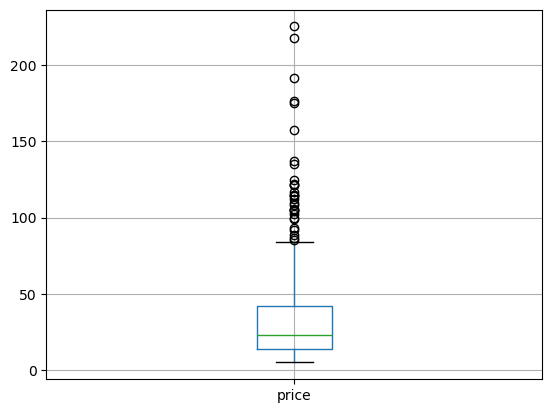

In [55]:
df_final.boxplot(column="price")
plt.savefig("boxplot1.png")
plt.show()


In [56]:
#Autre méthode avec plotly express
px.box(data_frame=df_final,x="price")

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2 - Exploration par l'utilisation de méthodes statistiques</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.1 - Identification par le Z-index</h3>
</div>

In [57]:
#Calculer la moyenne du prix
#Calculer l'écart-type du prix
#Calculer le Z-score
mean_price = df_final['price'].mean()
print(mean_price)


32.33368347338936


In [58]:
std_price = df_final['price'].std()
print(std_price)

27.5963324191972


In [59]:
df_final['z_score'] = (df_final['price'] - mean_price) / std_price
print(df_final['z_score'])

0     -0.860030
1      0.314039
2      0.241565
3      0.998912
4     -0.356340
         ...   
728    0.930063
729    0.930063
730    2.162110
731    0.814105
735   -0.265748
Name: z_score, Length: 714, dtype: float64


In [60]:
#Quel est le seuil prix dont le z-score est supérieur à 3?
outliers = df_final[df_final['z_score'].abs() > 3]["price"]
print(f"le seuil prix dont z_score superieur a 3 est {outliers.max()} EUR")

le seuil prix dont z_score superieur a 3 est 225.0 EUR


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.2 - Identification par l'intervalle interquartile</h3>
</div>

In [61]:
#Utilisation de la fonction "describe" de Pandas pour l'étude des mesures de dispersion
df_final['price'].describe()

count    714.000000
mean      32.333683
std       27.596332
min        5.200000
25%       14.062500
50%       23.450000
75%       42.075000
max      225.000000
Name: price, dtype: float64

In [62]:
#Définir un seuil pour les articles "outliers" en prix
# Calcul IQR
Q1 = df_final['price'].quantile(0.25)
Q3 = df_final['price'].quantile(0.75)
IQR = Q3 - Q1


# Seuils
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Détection des outliers
df_final['is_outlier'] = (df_final['price'] < lower_bound) | (df_final['price'] > upper_bound)
outliers_iqr = df_final[df_final['is_outlier']==True]["price"]
print(f"nous avons detecte {len(outliers_iqr)} outliers")
print(outliers_iqr.to_list())


nous avons detecte 31 outliers
[108.5, 104.0, 176.0, 157.0, 99.0, 105.0, 88.4, 115.0, 105.0, 109.6, 85.6, 86.8, 112.0, 115.0, 137.0, 217.5, 105.6, 114.0, 93.0, 122.0, 102.3, 124.8, 135.0, 191.3, 121.0, 121.0, 116.4, 175.0, 100.0, 225.0, 92.0]


In [63]:
#Définir le nombre d'articles et la proportion de l'ensemble du catalogue "outliers"
# Nombre total d'articles
total = len(df_final)

# Nombre d'outliers
nb_outliers = df_final['is_outlier'].sum()

# Proportion
proportion = nb_outliers / total

print(f"Outliers: {nb_outliers}")
print(f"Proportion: {proportion:.2%}")

Outliers: 31
Proportion: 4.34%


In [64]:
#Selon vous, ces outliers sont-ils justifiés ? Comment le démontrer si cela est possible ?
print("ces outliers sont bien justifies parceque il exist les bouteilles des vins excessivement cheres")


ces outliers sont bien justifies parceque il exist les bouteilles des vins excessivement cheres


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Analyse univariée du CA, des quantités vendues, des stocks et de la marge ainsi qu'une analyse multivariée  </h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.1 - Analyse des ventes en CA</h3>
</div>

In [65]:
df_final.head()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,rating_count,average_rating,total_sales,post_date,product_type,post_title,post_status,post_name,post_type,comment_count,z_score,is_outlier
0,4729.0,1.0,8.6,26.0,instock,4.22,38,0.0,0.0,10.0,2018-04-18 12:25:58,Vin,Emile Boeckel Crémant Brut Blanc de Blancs,publish,emile-boeckel-cremant-brut-blanc-de-blancs,product,0.0,-0.860030,False
1,4634.0,1.0,41.0,11.0,instock,20.12,41,0.0,0.0,6.0,2018-04-14 12:01:43,Vin,Marcel Windholtz Eau de Vie de Marc de Gewurzt...,publish,marcel-windholtz-eau-de-marc-de-gewurztraminer,product,0.0,0.314039,False
2,4141.0,1.0,39.0,123.0,instock,24.86,304,0.0,0.0,8.0,2018-02-13 12:57:44,Champagne,Champagne Gosset Grande Réserve,publish,gosset-champagne-grande-reserve,product,0.0,0.241565,False
3,5932.0,1.0,59.9,13.0,instock,27.18,523,0.0,0.0,0.0,2019-04-06 15:25:58,Cognac,Cognac Normandin Mercier VFC,publish,cognac-normandin-mercier-vfc,product,0.0,0.998912,False
4,5047.0,1.0,22.5,76.0,instock,13.78,531,0.0,0.0,8.0,2018-07-18 15:58:02,Champagne,Champagne Petit Lebrun &amp; Fils Blanc de Bla...,publish,champagne-petit-lebrun-fils-blanc-de-blancs-gr...,product,0.0,-0.356340,False


In [66]:
##############################
# Calculer le CA du site web #
##############################

#Créer une colonne calculant le CA par article
df_final["ca_par_article"]=df_final["price"]*df_final["total_sales"]


#Calculer la somme de la colonne "ca_par_article"
#Ce résultat correspond au chiffre d'affaire du site web
ca_total=df_final["ca_par_article"].sum()
print(f"le chiffre d'affaire du site est de : {ca_total} EUR")

le chiffre d'affaire du site est de : 143680.1 EUR


In [67]:
###############################
# Palmarès des articles en CA #
###############################

#Effectuer le tri dans l'ordre décroissant du CA du dataset df_merge
df_sorted = df_final.sort_values(by='price',ascending=False)

#Réinitialiser l'index du dataset par un reset_index
df_sorted=df_sorted.reset_index()

#Afficher les 20 premiers articles en CA
top20 = df_sorted.head(20)
display(top20)

#Graphique en barre des 20 premiers articles avec plotly express
px.bar(data_frame=top20,y="post_name",x="price")

,index,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,rating_count,average_rating,...,post_date,product_type,post_title,post_status,post_name,post_type,comment_count,z_score,is_outlier,ca_par_article
0,567,4352.0,1.0,225.0,0.0,outofstock,137.81,15940,0.0,0.0,...,2018-03-02 10:30:04,Champagne,Champagne Egly-Ouriet Grand Cru Millésimé 2008,publish,champagne-egly-ouriet-grand-cru-millesime-2008,product,0.0,6.981591,True,2475.0
1,204,5001.0,1.0,217.5,18.0,instock,116.87,14581,0.0,0.0,...,2018-07-17 09:45:39,Vin,David Duband Charmes-Chambertin Grand Cru 2014,publish,david-duband-charmes-chambertin-grand-cru-2014,product,0.0,6.709816,True,435.0
2,269,5892.0,1.0,191.3,98.0,instock,116.06,14983,0.0,0.0,...,2019-03-28 10:21:36,Champagne,Coteaux Champenois Egly-Ouriet Ambonnay Rouge ...,publish,coteaux-champenois-egly-ouriet-ambonnay-rouge-...,product,0.0,5.760415,True,1147.8
3,24,4402.0,1.0,176.0,11.0,instock,78.25,3510,0.0,0.0,...,2018-03-22 11:21:05,Cognac,Cognac Frapin VIP XO,publish,cognac-frapin-vip-xo,product,0.0,5.205993,True,528.0
4,313,5767.0,1.0,175.0,12.0,instock,90.42,15185,0.0,0.0,...,2019-03-13 14:43:22,Vin,Camille Giroud Clos de Vougeot 2016,publish,camille-giroud-clos-de-vougeot-2016,product,0.0,5.169756,True,700.0
5,33,4406.0,1.0,157.0,12.0,instock,69.08,7819,0.0,0.0,...,2018-03-22 11:42:48,Cognac,Cognac Frapin Château de Fontpinot 1989 20 Ans...,publish,cognac-frapin-chateau-de-fontpinot-1989-20-ans,product,0.0,4.517496,True,628.0
6,171,4904.0,1.0,137.0,9.0,instock,67.95,14220,0.0,0.0,...,2018-05-15 10:23:41,Vin,Domaine Des Croix Corton Charlemagne Grand Cru...,publish,domaine-des-croix-corton-charlemagne-grand-cru...,product,0.0,3.792762,True,411.0
7,257,6126.0,1.0,135.0,138.0,instock,80.33,14923,0.0,0.0,...,2019-06-28 17:22:27,Champagne,Champagne Gosset Célébris Vintage 2007,publish,champagne-gosset-celebris-vintage-2007,product,0.0,3.720288,True,675.0
8,256,5612.0,1.0,124.8,19.0,instock,66.41,14915,0.0,0.0,...,2019-01-15 15:30:49,Vin,Domaine Weinbach Gewurztraminer Grand Cru Furs...,publish,domaine-weinbach-gewurztraminer-gc-furstentum-...,product,0.0,3.350674,True,124.8
9,235,5917.0,1.0,122.0,12.0,instock,54.24,14775,0.0,0.0,...,2019-04-04 16:49:37,Whisky,Wemyss Malts Single Cask Scotch Whisky Choc 'n...,publish,wemyss-malts-single-cask-scotch-whisky-choc-n-...,product,0.0,3.249211,True,366.0


In [68]:
#############################
# Calculer le 20 / 80 en CA #
#############################

#Créer une colonne calculant la part du CA de la ligne dans le dataset
df_final.sort_values("ca_par_article",ascending=False,inplace=True)
#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée
df_final["ca_cumul"] = df_final["ca_par_article"].cumsum()
#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% du CA
df_final["ca_cumul_%"]=df_final["ca_cumul"]/df_final["ca_par_article"].sum()
n_article_80 = len(df_final[df_final["ca_cumul_%"]<= 0.8])
print(f"les nombres d'articles representant 80% du CA est de: {n_article_80} articles ")
#Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web
print(f"soit une proportion de {round(n_article_80/len(df_final)*100,2)}% de tous les articles")

les nombres d'articles representant 80% du CA est de: 434 articles 
soit une proportion de 60.78% de tous les articles


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.2 - Analyse des ventes en quantité</h3>
</div>

In [69]:
#####################################
# Palmarès des articles en quantité #
#####################################

#Effectuer le tri dans l'ordre décroissant de quantités vendues du dataset df_merge
df_sorted_qte = df_final.sort_values(by="total_sales",ascending=False)
#Réinitialiser l'index du dataset par un reset_index
df_sorted_qte = df_sorted_qte.reset_index(drop=True)
#Afficher les 20 premiers articles en quantité
top20_qte = df_sorted_qte.head(20)
display(top20_qte)
#Graphique en barre des 20 premiers articles avec plotly express
px.bar(data_frame=top20_qte,x="total_sales",y="post_name")


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,rating_count,average_rating,total_sales,...,post_title,post_status,post_name,post_type,comment_count,z_score,is_outlier,ca_par_article,ca_cumul,ca_cumul_%
0,4867.0,1.0,9.9,121.0,instock,4.86,16148,0.0,0.0,36.0,...,Château De La Selve IGP Coteaux de l'Ardèche M...,publish,chateau-de-la-selve-igp-coteaux-de-lardeche-ma...,product,0.0,-0.812923,False,356.4,32758.10,0.227993
1,4203.0,1.0,9.9,74.0,instock,5.01,15415,0.0,0.0,27.0,...,Mas Laval IGP Pays d'Hérault Les Pampres Blanc...,publish,mas-laval-igp-pays-herault-pampres-blanc-2018,product,0.0,-0.812923,False,267.3,57815.50,0.402390
2,4275.0,1.0,14.9,62.0,instock,7.78,14864,0.0,0.0,24.0,...,I Fabbri Chianti Classico Lamole 2017,publish,i-fabbri-chianti-classico-lamole-2017,product,0.0,-0.631739,False,357.6,30973.90,0.215575
3,4726.0,1.0,12.7,0.0,outofstock,6.82,14950,0.0,0.0,22.0,...,François Baur Pinot Noir Schlittweg 2017,publish,francois-baur-pinot-noir-schlittweg-2017,product,0.0,-0.711460,False,279.4,52884.80,0.368073
4,4647.0,1.0,28.5,45.0,instock,14.14,16525,0.0,0.0,22.0,...,Bernard Baudry Chinon Rouge La Croix Boissée 2017,publish,bernard-baudry-chinon-rouge-croix-boissee-2017,product,0.0,-0.138920,False,627.0,11816.60,0.082242
5,5826.0,1.0,41.2,34.0,instock,21.71,15325,0.0,0.0,20.0,...,Agnès Levet Côte Rôtie Améthyste 2017,publish,agnes-levet-amethyste-2017,product,0.0,0.321286,False,824.0,5559.80,0.038696
6,6129.0,1.0,5.2,68.0,instock,2.74,14570,0.0,0.0,20.0,...,Moulin de Gassac IGP Pays d'Hérault Guilhem Bl...,publish,moulin-de-gassac-igp-pays-dherault-guilhem-bla...,product,0.0,-0.983235,False,104.0,136883.80,0.952698
7,4220.0,1.0,11.6,48.0,instock,5.75,15758,0.0,0.0,18.0,...,Xavier Frissant Touraine Amboise Chenin Les Pi...,publish,frissant-chenin-pierres-2018,product,0.0,-0.751320,False,208.8,83191.85,0.579007
8,6569.0,1.0,29.0,58.0,instock,15.28,15705,0.0,0.0,17.0,...,Decelle-Villa Chorey-Lès-Beaune 2016,publish,decelle-villa-chorey-beaune-2016,product,0.0,-0.120802,False,493.0,17849.30,0.124229
9,5778.0,1.0,5.8,44.0,instock,3.09,15561,0.0,0.0,17.0,...,Maurel Pays d'Oc Merlot 2018,publish,maurel-pays-d-oc-merot-2018,product,0.0,-0.961493,False,98.6,139014.00,0.967524


In [70]:
#############################
# Calculer le 20 / 80 en quantite
#############################

#Créer une colonne calculant la part en quantité de la ligne dans le dataset
df_sorted_qte["part_qty"] = df_sorted_qte["total_sales"]/df_sorted_qte["total_sales"].sum()
#Créer une colonne réalisant la somme cumulative de la colonne précedemment créée
df_sorted_qte["cumul_qty"]=df_sorted_qte["part_qty"].cumsum()
#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% des ventes en quantité
df_80_qte = df_sorted_qte[df_sorted_qte["cumul_qty"]<=0.80]
nb_article_80_qte = len(df_80_qte)
print(f"les nombres d'articles representant 80% du CA est de: {nb_article_80_qte} articles")
#Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web
print(f"soit une proportion de {round(nb_article_80_qte/len(df_sorted_qte)*100,2)}% de tous les articles")


les nombres d'articles representant 80% du CA est de: 433 articles
soit une proportion de 60.64% de tous les articles


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.3 - Analyse des stocks</h3>
</div>

In [71]:
######################################
# Calculer le nombre de mois de stock #
######################################

#Import de numpy 
import numpy as np
#Création de la colonne Rotation de stock
df_final["rotation_stock"] = df_final["stock_quantity"] / df_final["total_sales"]
#Remplacement des "inf" par 0
df_final["rotation_stock"] = df_final["rotation_stock"].replace(np.inf,0)
#Effectuer le tri dans l'ordre décroissant du nombre de mois de stock dans le dataset df_merge
df_final_sort = df_final.sort_values(by="rotation_stock",ascending=False)
df_final_sort = df_final_sort.reset_index(drop=True)
#Graphique en barre du flop 20 des produits qui ont le plus de mois de stock
flop20_qte =df_final_sort.head(20)
display(flop20_qte)
px.bar(data_frame=flop20_qte,x="rotation_stock",y="post_name")

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,rating_count,average_rating,total_sales,...,post_status,post_name,post_type,comment_count,z_score,is_outlier,ca_par_article,ca_cumul,ca_cumul_%,rotation_stock
0,4142.0,1.0,53.0,125.0,instock,32.15,11641,0.0,0.0,4.0,...,publish,champagne-gosset-grand-millesime-2006,product,0.0,0.748879,False,212.0,80878.35,0.562906,31.250000
1,6126.0,1.0,135.0,138.0,instock,80.33,14923,0.0,0.0,5.0,...,publish,champagne-gosset-celebris-vintage-2007,product,0.0,3.720288,True,675.0,9256.00,0.064421,27.600000
2,4356.0,1.0,51.6,81.0,instock,31.00,12585,0.0,0.0,3.0,...,publish,champagne-egly-ouriet-premier-cru-vrigny,product,0.0,0.698148,False,154.8,109943.20,0.765194,27.000000
3,4348.0,1.0,59.0,125.0,instock,34.76,12586,0.0,0.0,5.0,...,publish,champagne-egly-ouriet-tradition-grand-cru,product,0.0,0.966299,False,295.0,47722.80,0.332146,25.000000
4,4148.0,1.0,37.5,71.0,instock,21.88,1364,0.0,0.0,3.0,...,publish,champagne-mailly-grand-cru-brut-rose,product,0.0,0.187210,False,112.5,132987.90,0.925583,23.666667
5,4357.0,1.0,39.0,115.0,instock,22.30,9562,0.0,0.0,5.0,...,publish,champagne-larmandier-bernier-latitude,product,0.0,0.241565,False,195.0,89397.65,0.622199,23.000000
6,4144.0,1.0,49.0,91.0,instock,27.73,1662,0.0,0.0,4.0,...,publish,champagne-gosset-grand-rose,product,0.0,0.603932,False,196.0,88420.15,0.615396,22.750000
7,5025.0,1.0,112.0,136.0,instock,68.60,13914,0.0,0.0,6.0,...,publish,champagne-agrapart-fils-lavizoise-grand-cru-20...,product,0.0,2.886844,True,672.0,9928.00,0.069098,22.666667
8,4350.0,1.0,79.5,145.0,instock,47.30,12588,0.0,0.0,7.0,...,publish,champagne-egly-ouriet-extra-brut-vp,product,0.0,1.709152,False,556.5,14764.30,0.102758,20.714286
9,4150.0,1.0,59.0,123.0,instock,35.45,1366,0.0,0.0,6.0,...,publish,champagne-mailly-grand-cru-intemporelle-2010,product,0.0,0.966299,False,354.0,33468.10,0.232935,20.500000


In [72]:
####################################
# Valorisation des stocks en euros #
####################################

#Création de la colonne Valorisation des stocks en euros
df_final["valorisation_stock_euros"] = df_final["price"] * df_final["stock_quantity"]
#Calculer la somme de la colonne "Valorisation_stock_euros"
total_stock_value = df_final["valorisation_stock_euros"].sum()
print("la somme de la valuation in euros: " + str(round(total_stock_value, 2)) + " euros")

la somme de la valuation in euros: 494682.4 euros


In [73]:
##############################################
# Valorisation du nombre de produits en stock #
##############################################

#Calculer la somme de la colonne stock quantity
total_stock_qty = df_final['stock_quantity'].sum()
print("le nombre des pieces en stock: " + str(int(total_stock_qty)))


le nombre des pieces en stock: 16741


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.4 - Analyse du taux de marge</h3>
</div>

In [74]:
############################
# Analyse du taux de marge #
############################

#Création de la colonne Prix HT
df_final["prix_ht"] = df_final["price"] /1.20
#Création de la colonne Taux de marge
df_final ["taux_de_marge"] = (df_final['prix_ht'] - df_final['purchase_price']) / df_final['prix_ht']
#Afficher le prix minimum de la colonne "taux_marge"
taux_de_marge = df_final["taux_de_marge"].min()
print("taux_marge minimum est: " + str(round(taux_de_marge, 2)))
#Afficher le prix maximum de la colonne "taux_marge"
taux_de_marge = df_final["taux_de_marge"].max()
print("taux_marge maximum est: " + str(round(taux_de_marge, 2)))


taux_marge minimum est: -6.35
taux_marge maximum est: 0.48


In [75]:
#Affichage de la ligne avec un taux de marge inférieur à 0
taux_de_marge_neg = df_final[df_final["taux_de_marge"] < 0]
print("Number of items with a negative margin: " + str(len(taux_de_marge_neg)))
taux_de_marge_neg

Number of items with a negative margin: 1


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,rating_count,average_rating,total_sales,...,comment_count,z_score,is_outlier,ca_par_article,ca_cumul,ca_cumul_%,rotation_stock,valorisation_stock_euros,prix_ht,taux_de_marge
79,4355.0,1.0,12.65,97.0,instock,77.48,12589,0.0,0.0,0.0,...,0.0,-0.713272,False,0.0,143680.1,1.0,0.0,1227.05,10.541667,-6.349881


In [76]:
#Création d'un dataframe avec les taux positifs
taux_de_marge_pos = df_final[df_final["taux_de_marge"]>= 0]
#Afficher le prix minimum de la colonne "taux_marge"
taux_marge_min = taux_de_marge_pos["taux_de_marge"].min()
print("taux_marge_min est :"+str(round(taux_marge_min, 2)) + "%")
#Afficher le prix maximum de la colonne "taux_marge"
taux_marge_max = taux_de_marge_pos["taux_de_marge"].max()
print("taux_marge_max est :"+str(round(taux_marge_max, 2)) + "%")

taux_marge_min est :0.23%
taux_marge_max est :0.48%


In [77]:
#Création d'un dataframe avec le taux de marge moyen par type de produit
taux_de_marge_moyen = taux_de_marge_pos.groupby('product_type')['taux_de_marge'].mean()
taux_de_marge_moyen = taux_de_marge_moyen.reset_index()
print("le taux de marge moyen par type de produit:")
print(taux_de_marge_moyen)
#Affichage dans un graphique du taux de marge par type de produit
fig = px.bar(taux_de_marge_moyen, x='product_type', y='taux_de_marge', title='le taux de marge moyen par type de produit')
fig.show()


le taux de marge moyen par type de produit:
    product_type  taux_de_marge
0      Champagne       0.284885
1         Cognac       0.450676
2            Gin       0.428000
3  Huile d'olive       0.249982
4            Vin       0.380123
5         Whisky       0.449189


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.5 - Analyse des corrélations entre les variables stock, sales et price</h3>
</div>

                stock_quantity  total_sales     price
stock_quantity        1.000000     0.438958 -0.106633
total_sales           0.438958     1.000000 -0.516258
price                -0.106633    -0.516258  1.000000


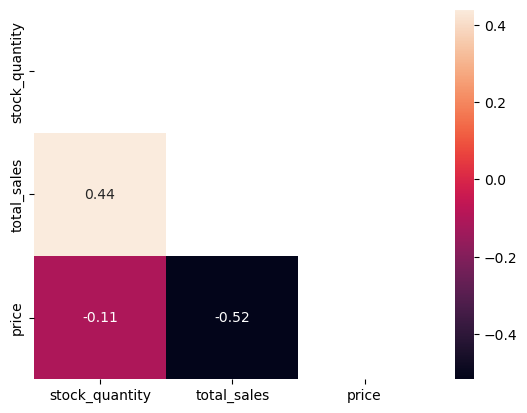

In [80]:
############################
# Analyse des corrélations #
############################

#Importation de Seaborn
import seaborn as sns
#Création d'une heatmap de corrélation avec les variables stock, sales et price
corrélation = ['stock_quantity','total_sales','price']
df_corr = df_final[corrélation]
corrélation_matrix = df_corr.corr()
print(corrélation_matrix)
#On peut également créer un mask pour n'afficher qu'une demi heatmap
mask = np.triu(np.ones_like(corrélation_matrix,dtype=bool))
plt.figure()
sns.heatmap(corrélation_matrix,mask=mask, annot=True)
plt.savefig("boxplot2.png")
plt.show()

#Que peut-on conclure des corrélations ?
on note ses trois variables sont pas fortement correlees.Total_sales et price sont moyennement correlees de maniere negetive.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.6 - Mise à disposition de la nouvelle table sur un fichier Excel</h3>
</div>

In [79]:
#Mettre le dataset df_merge sur un fichier Excel
#Cette étape peut être utile pour partager le résultat du dataset obtenu avec les équipes.  
df_final.to_excel("final_data.xlsx",index=False)